# Cell counts per CT in Anatomogram and HRApop

This notebook creates a simple descriptive comparison of cell counts per Cell Ontology (CL) term between the Anatomogram cell-instance data and HRApop sc-transcriptomics cell summaries.

CTs are aligned using the CL ID. Cell-type labels are used only for display. HRApop entries with ASCTB-TEMP identifiers therefore cannot be matched to an Anatomogram CT by label in this figure.


## 0. Imports

In [24]:
from pathlib import Path
import gzip
import json
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


## 1. Configuration

The notebook is intended to be run from the anatomogram-comparison directory in the HRA publication project. The Anatomogram and HRApop inputs are in sibling/project folders.


In [25]:
# -----------------------------------------------------------------------------
# Input files
# -----------------------------------------------------------------------------

INPUT_FILE = Path(
    "../anatomogram-data/"
    "anatomogram-sc-transcriptomics-cell-instances.csv.gz"
)

HRAPOP_FILE = Path(
    "../data-preprocessor/input/"
    "sc-transcriptomics-cell-summaries.jsonl.gz"
)


# -----------------------------------------------------------------------------
# Output
# -----------------------------------------------------------------------------

OUTPUT_DIR = Path("ctann_vs_author_results") / "cell_counts"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FIGURE_DIR = OUTPUT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)


# -----------------------------------------------------------------------------
# HRApop annotation methods present in the summary file
# -----------------------------------------------------------------------------

HRAPOP_TOOLS = [
    "celltypist",
    "azimuth",
    "popv",
]

TOOL_LABELS = {
    "author": "Anatomogram author",
    "celltypist": "HRApop - CellTypist",
    "azimuth": "HRApop - Azimuth",
    "popv": "HRApop - popV",
}


# -----------------------------------------------------------------------------
# Publication-ready palette
# -----------------------------------------------------------------------------

COLORS = {
    "author": "#4D4D4D",
    "celltypist": "#0072B2",
    "azimuth": "#56B4E9",
    "popv": "#D55E00",
}


# -----------------------------------------------------------------------------
# Cell Ontology helper
# -----------------------------------------------------------------------------

CL_RE = re.compile(r"^CL:\d+$")


def is_cl_id(value):
    if pd.isna(value):
        return False

    return bool(
        CL_RE.match(
            str(value).strip()
        )
    )


# -----------------------------------------------------------------------------
# Validate inputs
# -----------------------------------------------------------------------------

if not INPUT_FILE.exists():
    raise FileNotFoundError(
        "Could not find Anatomogram input: "
        f"{INPUT_FILE.resolve()}"
    )

if not HRAPOP_FILE.exists():
    raise FileNotFoundError(
        "Could not find HRApop input: "
        f"{HRAPOP_FILE.resolve()}"
    )

print("Anatomogram input:")
print(" ", INPUT_FILE.resolve())
print()
print("HRApop input:")
print(" ", HRAPOP_FILE.resolve())
print()
print("Output directory:")
print(" ", OUTPUT_DIR.resolve())


Anatomogram input:
  /Users/sbidanta/projects/HRA/Publication/hra-ftu-explorer-supporting-information/anatomogram-data/anatomogram-sc-transcriptomics-cell-instances.csv.gz

HRApop input:
  /Users/sbidanta/projects/HRA/Publication/hra-ftu-explorer-supporting-information/data-preprocessor/input/sc-transcriptomics-cell-summaries.jsonl.gz

Output directory:
  /Users/sbidanta/projects/HRA/Publication/hra-ftu-explorer-supporting-information/anatomogram-comparison/ctann_vs_author_results/cell_counts


## 2. Load Anatomogram author annotations and count cells per CT

The Anatomogram file is a cell-level table. A biological cell is identified by `(dataset, cell)`. We use only `tool == 'author'` for this descriptive comparison and count unique cells per exact CL ID.


In [26]:
def load_anatomogram_author_counts(path):
    df = pd.read_csv(
        path,
        dtype=str,
    )

    required = {
        "dataset",
        "cell",
        "tool",
        "cell_id",
        "cell_label",
    }

    missing = required - set(df.columns)

    if missing:
        raise ValueError(
            "Anatomogram file is missing required columns: "
            f"{sorted(missing)}"
        )

    author = df[
        df["tool"] == "author"
    ].copy()

    author = author.drop_duplicates(
        subset=[
            "dataset",
            "cell",
        ]
    )

    counts = (
        author.groupby(
            [
                "cell_id",
                "cell_label",
            ],
            as_index=False,
            dropna=False,
        )
        .size()
        .rename(
            columns={
                "size": "cell_count"
            }
        )
    )

    return counts


anatomogram_author_counts = load_anatomogram_author_counts(
    INPUT_FILE
)

anatomogram_author_counts.to_csv(
    OUTPUT_DIR / "anatomogram_author_ct_counts.csv",
    index=False,
)

display(
    anatomogram_author_counts
    .sort_values(
        "cell_count",
        ascending=False,
    )
    .head(20)
)


,cell_id,cell_label,cell_count
7,CL:0000084,T cell,7854
30,CL:0002306,epithelial cell of proximal tubule,5481
45,CL:1001106,kidney loop of Henle thick ascending limb epit...,4431
43,CL:1000849,kidney distal convoluted tubule epithelial cell,3249
39,CL:1000398,endothelial cell of hepatic sinusoid,2337
42,CL:1000768,kidney connecting tubule epithelial cell,1805
16,CL:0000235,macrophage,1635
47,CL:1001603,lung macrophage,1180
34,CL:0005011,renal alpha-intercalated cell,1107
33,CL:0005009,renal principal cell,1022


## 3. Load HRApop sc-transcriptomics cell summaries

The HRApop input is a gzip-compressed JSON Lines file. Each line is one summary record. The CT-specific values are stored inside its nested `summary` array.


In [27]:
def load_hrapop_jsonl(path):
    records = []

    with gzip.open(
        path,
        "rt",
        encoding="utf-8",
    ) as handle:

        for line_number, line in enumerate(
            handle,
            start=1,
        ):
            line = line.strip()

            if not line:
                continue

            try:
                records.append(
                    json.loads(line)
                )
            except json.JSONDecodeError as exc:
                raise ValueError(
                    f"Invalid JSON on line {line_number} "
                    f"of {path}"
                ) from exc

    return records


hrapop_records = load_hrapop_jsonl(
    HRAPOP_FILE
)

print(
    f"HRApop records: {len(hrapop_records):,}"
)

if hrapop_records:
    print()
    print("Example top-level keys:")
    for key in hrapop_records[0].keys():
        print(" ", key)


HRApop records: 12,999

Example top-level keys:
  @type
  annotation_method
  modality
  cell_source
  summary


## 4. Inspect HRApop annotation methods and summary structure

Before aggregation, inspect the annotation methods represented in the HRApop file and confirm that the CT summaries contain `cell_id`, `cell_label`, `count`, and `percentage`.


In [28]:
annotation_methods = sorted({
    str(
        record.get(
            "annotation_method",
            "",
        )
    ).strip().lower()
    for record in hrapop_records
    if record.get("annotation_method")
})

print("HRApop annotation methods:")
for method in annotation_methods:
    print(" ", method)


if hrapop_records:
    first_summary = hrapop_records[0].get(
        "summary",
        [],
    )

    if isinstance(first_summary, list) and first_summary:
        print()
        print("Example summary keys:")
        for key in first_summary[0].keys():
            print(" ", key)


HRApop annotation methods:
  azimuth
  celltypist
  popv

Example summary keys:
  cell_id
  cell_label
  gene_expr
  count
  @type
  percentage


## 5. Extract CT counts from HRApop

The HRApop summary stores a `count` for each CT within each summary record. We preserve `annotation_method` and `cell_source` during extraction for auditability. Counts are kept as floats because the source file can contain non-integer summary values.


In [29]:
def extract_hrapop_summary_rows(records):
    rows = []

    for record_number, record in enumerate(
        records,
        start=1,
    ):
        if not isinstance(record, dict):
            continue

        annotation_method = str(
            record.get(
                "annotation_method",
                "",
            )
        ).strip().lower()

        modality = str(
            record.get(
                "modality",
                "",
            )
        ).strip()

        cell_source = str(
            record.get(
                "cell_source",
                "",
            )
        ).strip()

        sex = record.get(
            "sex",
            "",
        )

        summary = record.get(
            "summary",
            [],
        )

        if isinstance(summary, dict):
            summary = [summary]

        if not isinstance(summary, list):
            continue

        for item in summary:
            if not isinstance(item, dict):
                continue

            cell_id = str(
                item.get(
                    "cell_id",
                    "",
                )
            ).strip()

            cell_label = str(
                item.get(
                    "cell_label",
                    "",
                )
            ).strip()

            count = item.get(
                "count"
            )

            percentage = item.get(
                "percentage"
            )

            if not cell_id:
                continue

            try:
                cell_count = float(count)
            except (
                TypeError,
                ValueError,
            ):
                continue

            try:
                percentage = float(
                    percentage
                )
            except (
                TypeError,
                ValueError,
            ):
                percentage = np.nan

            rows.append({
                "record_number": record_number,
                "annotation_method": annotation_method,
                "modality": modality,
                "cell_source": cell_source,
                "sex": sex,
                "cell_id": cell_id,
                "cell_label": cell_label,
                "cell_count": cell_count,
                "percentage": percentage,
            })

    if not rows:
        raise ValueError(
            "No CT summary rows could be extracted from HRApop."
        )

    return pd.DataFrame(rows)


hrapop_raw = extract_hrapop_summary_rows(
    hrapop_records
)

hrapop_raw.to_csv(
    OUTPUT_DIR / "hrapop_ct_counts_raw.csv",
    index=False,
)

print(
    f"Extracted HRApop CT summary rows: {len(hrapop_raw):,}"
)

display(
    hrapop_raw.head(20)
)


Extracted HRApop CT summary rows: 279,977


,record_number,annotation_method,modality,cell_source,sex,cell_id,cell_label,cell_count,percentage
0,1,celltypist,sc_transcriptomics,https://entity.api.hubmapconsortium.org/entiti...,,ASCTB-TEMP:proximal-progenitor,Proximal progenitor,64.0,0.010667
1,1,celltypist,sc_transcriptomics,https://entity.api.hubmapconsortium.org/entiti...,,ASCTB-TEMP:goblet-cell,Goblet cell,315.0,0.052500
2,1,celltypist,sc_transcriptomics,https://entity.api.hubmapconsortium.org/entiti...,,ASCTB-TEMP:enterocyte,Enterocyte,3914.0,0.652333
3,1,celltypist,sc_transcriptomics,https://entity.api.hubmapconsortium.org/entiti...,,ASCTB-TEMP:best2-goblet-cell,BEST2+ Goblet cell,16.0,0.002667
4,1,celltypist,sc_transcriptomics,https://entity.api.hubmapconsortium.org/entiti...,,ASCTB-TEMP:mesoderm-1-hand1-,Mesoderm 1 (HAND1+),18.0,0.003000
5,1,celltypist,sc_transcriptomics,https://entity.api.hubmapconsortium.org/entiti...,,ASCTB-TEMP:eecs,EECs,198.0,0.033000
6,1,celltypist,sc_transcriptomics,https://entity.api.hubmapconsortium.org/entiti...,,ASCTB-TEMP:activated-t,Activated T,94.0,0.015667
7,1,celltypist,sc_transcriptomics,https://entity.api.hubmapconsortium.org/entiti...,,ASCTB-TEMP:trgv2-gdt,TRGV2 gdT,60.0,0.010000
8,1,celltypist,sc_transcriptomics,https://entity.api.hubmapconsortium.org/entiti...,,ASCTB-TEMP:trgv4-gdt,TRGV4 gdT,39.0,0.006500
9,1,celltypist,sc_transcriptomics,https://entity.api.hubmapconsortium.org/entiti...,,ASCTB-TEMP:best4-epithelial,BEST4+ epithelial,93.0,0.015500


## 6. Aggregate HRApop counts by annotation method and CL ID

For the paper figure, HRApop is treated as a collection of tool-specific CT summaries. We therefore aggregate by `annotation_method + cell_id` across the HRApop summary records.

We do not combine HRApop rows with Anatomogram rows under the same tool name. Dataset source and annotation method remain separate.

Only the three methods present in this HRApop file are retained: CellTypist, Azimuth, and popV.


In [30]:
hrapop_counts = hrapop_raw[
    hrapop_raw[
        "annotation_method"
    ].isin(HRAPOP_TOOLS)
].copy()

if hrapop_counts.empty:
    raise ValueError(
        "None of the expected HRApop annotation methods were found. "
        f"Expected: {HRAPOP_TOOLS}"
    )


# Aggregate by exact CL ID. Different HRApop labels that share the same
# CL identifier contribute to the same CT count.
hrapop_counts = (
    hrapop_counts
    .groupby(
        [
            "annotation_method",
            "cell_id",
        ],
        as_index=False,
    )
    .agg(
        cell_count=(
            "cell_count",
            "sum",
        ),
        hrapop_labels=(
            "cell_label",
            lambda values: " | ".join(
                sorted(
                    set(
                        str(v).strip()
                        for v in values
                        if str(v).strip()
                    )
                )
            ),
        ),
    )
)

hrapop_counts["is_cl_id"] = (
    hrapop_counts["cell_id"]
    .map(is_cl_id)
)

hrapop_counts.to_csv(
    OUTPUT_DIR / "hrapop_ct_counts_by_tool.csv",
    index=False,
)

print("HRApop methods:")
display(
    hrapop_counts[
        "annotation_method"
    ]
    .value_counts()
    .rename_axis("annotation_method")
    .to_frame("ct_rows")
)

print()
print("HRApop CT counts with formal CL IDs:")
display(
    hrapop_counts[
        hrapop_counts["is_cl_id"]
    ]
    .sort_values(
        "cell_count",
        ascending=False,
    )
    .head(20)
)


HRApop methods:


,ct_rows
annotation_method,
celltypist,265
azimuth,219
popv,155



HRApop CT counts with formal CL IDs:


,annotation_method,cell_id,cell_count,hrapop_labels,is_cl_id
569,popv,CL:0000897,2589351.0,"CD4-positive, alpha-beta memory T cell",True
565,popv,CL:0000860,2057053.0,classical monocyte,True
116,azimuth,CL:0000897,1915157.0,CD4 Memory | CD4 TCM,True
132,azimuth,CL:0002057,1713507.0,CD14 Mono,True
549,popv,CL:0000748,1442873.0,retinal bipolar neuron,True
502,popv,CL:0000057,1287681.0,fibroblast,True
543,popv,CL:0000625,1241751.0,"CD8-positive, alpha-beta T cell",True
185,azimuth,CL:1001109,1240133.0,Cortical Thick Ascending Limb,True
139,azimuth,CL:0002131,1232256.0,Ventricular Cardiomycoyte,True
539,popv,CL:0000499,1190790.0,stromal cell,True


## 7. Build the Anatomogram versus HRApop comparison table

For a direct paper comparison, the CTs are selected from the most abundant Anatomogram author CTs and aligned to HRApop by exact CL ID. The displayed CT label comes from the Anatomogram author annotation.

A zero in a HRApop column means that no HRApop summary with that exact CL ID was found for that annotation method. It does not imply that the biological label is absent under a temporary HRApop identifier.


In [31]:
TOP_N_CT = 20


top_author = (
    anatomogram_author_counts
    .sort_values(
        "cell_count",
        ascending=False,
    )
    .head(TOP_N_CT)
    .copy()
)


top_ct_ids = top_author[
    "cell_id"
].tolist()

label_lookup = (
    top_author
    .set_index("cell_id")[
        "cell_label"
    ]
    .to_dict()
)


author_counts = (
    top_author[
        [
            "cell_id",
            "cell_count",
        ]
    ]
    .rename(
        columns={
            "cell_count": "Anatomogram author"
        }
    )
    .set_index("cell_id")
)


hrapop_plot = (
    hrapop_counts[
        hrapop_counts["cell_id"].isin(
            top_ct_ids
        )
    ]
    .pivot_table(
        index="cell_id",
        columns="annotation_method",
        values="cell_count",
        aggfunc="sum",
        fill_value=0,
    )
)

hrapop_plot = hrapop_plot.reindex(
    index=top_ct_ids,
    columns=HRAPOP_TOOLS,
    fill_value=0,
)

hrapop_plot = hrapop_plot.rename(
    columns={
        "celltypist": "HRApop - CellTypist",
        "azimuth": "HRApop - Azimuth",
        "popv": "HRApop - popV",
    }
)


comparison = author_counts.join(
    hrapop_plot,
    how="left",
).fillna(0)

comparison["cell_label"] = comparison.index.map(
    label_lookup
)

comparison = comparison.reset_index()

comparison = comparison[
    [
        "cell_id",
        "cell_label",
        "Anatomogram author",
        "HRApop - CellTypist",
        "HRApop - Azimuth",
        "HRApop - popV",
    ]
]

comparison.to_csv(
    OUTPUT_DIR
    / "anatomogram_vs_hrapop_ct_counts.csv",
    index=False,
)

display(comparison)


,cell_id,cell_label,Anatomogram author,HRApop - CellTypist,HRApop - Azimuth,HRApop - popV
0,CL:0000084,T cell,7854,237807.0,173833.0,184117.0
1,CL:0002306,epithelial cell of proximal tubule,5481,0.0,0.0,0.0
2,CL:1001106,kidney loop of Henle thick ascending limb epit...,4431,0.0,0.0,0.0
3,CL:1000849,kidney distal convoluted tubule epithelial cell,3249,0.0,0.0,0.0
4,CL:1000398,endothelial cell of hepatic sinusoid,2337,0.0,0.0,38465.0
5,CL:1000768,kidney connecting tubule epithelial cell,1805,0.0,522267.0,0.0
6,CL:0000235,macrophage,1635,307715.0,119759.0,974278.0
7,CL:1001603,lung macrophage,1180,265774.0,0.0,0.0
8,CL:0005011,renal alpha-intercalated cell,1107,0.0,0.0,0.0
9,CL:0005009,renal principal cell,1022,0.0,0.0,0.0


## 8. Visualization

This figure compares the number of cells represented by the same exact CL IDs. The Anatomogram bar is the author annotation; HRApop bars are separated by annotation method because HRApop does not provide one single CT annotation source.


In [32]:
print(
    plot_df[source_columns].max()
)

print(
    plot_df[source_columns].min()
)

Anatomogram author       7854.0
HRApop - CellTypist    843263.0
HRApop - Azimuth       967029.0
HRApop - popV          974278.0
dtype: float64
Anatomogram author     380.0
HRApop - CellTypist      0.0
HRApop - Azimuth         0.0
HRApop - popV            0.0
dtype: float64


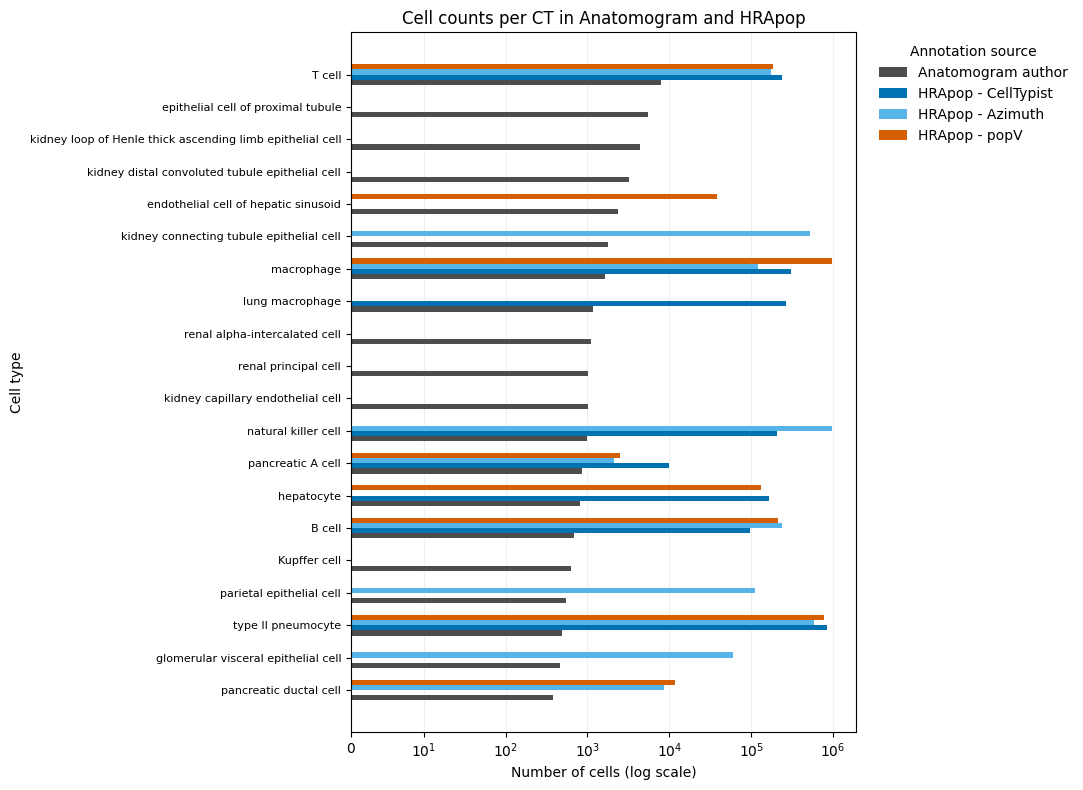

In [33]:
fig, ax = plt.subplots(
    figsize=(11, fig_height)
)


# -----------------------------------------------------------------------------
# Symmetric logarithmic x-axis
#
# Symlog is used because some HRApop CT counts are exactly zero.
# The same scale is applied to all annotation sources.
# -----------------------------------------------------------------------------

ax.set_xscale(
    "symlog",
    linthresh=10,
    linscale=0.8,
    base=10,
)


# -----------------------------------------------------------------------------
# Plot bars
# -----------------------------------------------------------------------------

for offset, source in zip(
    offsets,
    source_columns,
):

    values = plot_df[
        source
    ].to_numpy(
        dtype=float
    )

    ax.barh(
        y + offset,
        values,
        height=bar_height,
        color=source_colors[source],
        label=source,
    )


# -----------------------------------------------------------------------------
# Axes
# -----------------------------------------------------------------------------

ax.set_yticks(y)

ax.set_yticklabels(
    labels,
    fontsize=8,
)


ax.set_xlabel(
    "Number of cells (log scale)"
)

ax.set_ylabel(
    "Cell type"
)

ax.set_title(
    "Cell counts per CT in Anatomogram and HRApop"
)


ax.legend(
    title="Annotation source",
    frameon=False,
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)


ax.grid(
    axis="x",
    alpha=0.20,
)

ax.set_axisbelow(True)


fig.tight_layout()


fig.savefig(
    FIGURE_DIR
    / "cell_counts_per_ct_anatomogram_vs_hrapop.png",
    dpi=300,
    bbox_inches="tight",
)

fig.savefig(
    FIGURE_DIR
    / "cell_counts_per_ct_anatomogram_vs_hrapop.pdf",
    bbox_inches="tight",
)


plt.show()


## 9. Notes for the manuscript

The plotted counts are descriptive and should be interpreted as follows:

- Anatomogram counts are unique cell counts from the author annotation.
- HRApop counts are aggregated from HRApop sc-transcriptomics cell-summary records separately for CellTypist, Azimuth, and popV.
- CTs are aligned by exact CL ID; labels are not used to declare equivalence.
- HRApop temporary identifiers (`ASCTB-TEMP:*`) are not remapped in this descriptive figure.
- The figure compares CT concepts that can be aligned through an exact CL ID and retains zero counts when a selected Anatomogram CT has no matching HRApop CL ID for a particular method.
